!sage -i sympy для установки пакетов

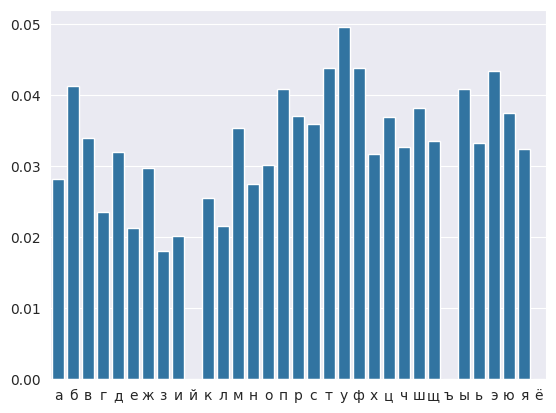

In [161]:
from my_crypto.src.text_analysis import *
alphabet=sorted('йцукенгшщзхъфывапролджёэячсмитьбю')

with open("../files/7.TXT", "r", encoding="IBM866") as file:
    text = file.read().lower().replace('ё', 'е')

text_analysis(text, 1, alphabet)

Как видим из картинки, буквы более-менее равновероятны + "ё" заменили на "е", "й" — на "и", "ъ" — на "ь"
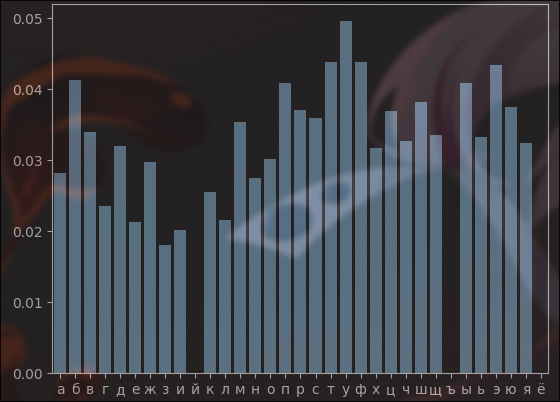

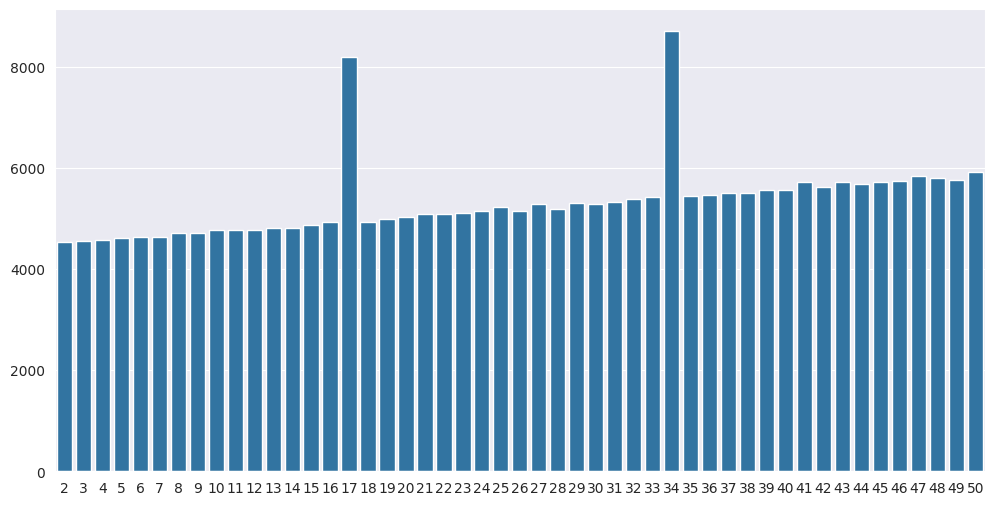

In [162]:
import seaborn
import matplotlib.pyplot as plt
alphabet=sorted('цукенгшщзхфывапролджэячсмитьбю')

text = text.replace(" ", '').replace("\n", '')

def create_teable(text, gamma_length, alphabet):
    table = [[0 for _ in range(gamma_length)] for _ in range(len(alphabet))]
    for i, letter in enumerate(text):
        table[alphabet.index(letter)][i%gamma_length] += 1
    return table

def v_j(table, j):
    return sum(table[j])

def v_i(table, i):
    sum = 0
    for column in table:
        # print(column)
        sum += column[i]
    return sum

def found_gamma_length(text, alphabet):
    dictionary = {}
    for gamma_length in range(2, 51):
        table = create_teable(text, gamma_length, alphabet)
        chi_2 = 1
        for i in range(gamma_length):
            for j in range(len(alphabet)):
               chi_2 += table[j][i]**2 / v_i(table, i) / v_j(table, j)
        chi_2 = len(text) * (chi_2 - 1)
        dictionary[gamma_length] = chi_2
        # if 6000 < chi_2:
        #     return gamma_length
    plt.figure(figsize=(12, 6))
    seaborn.barplot(dictionary)
    plt.show()

found_gamma_length(text, alphabet)

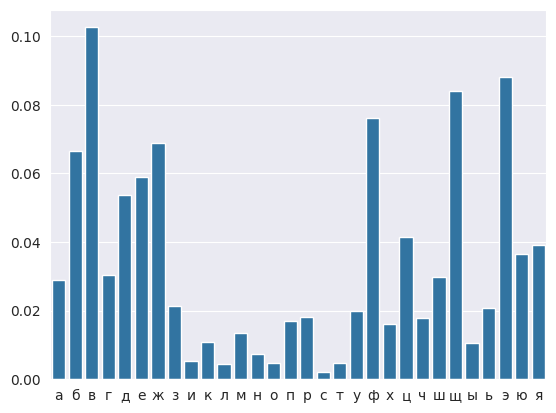

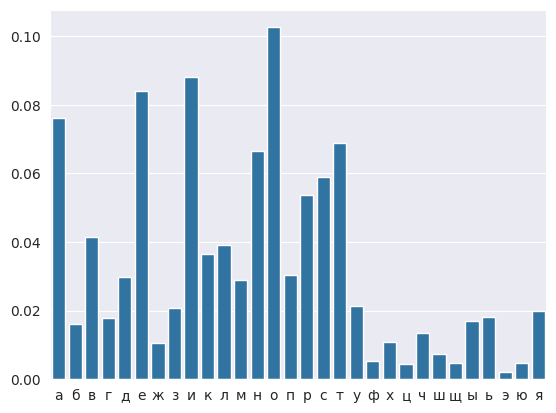

писателииученьеща
рлатаньиаферистьт
ьсячелетиямиразви
валинаукуосекрета
хдоводяихсоздание
доспвершенстваслу
зилитаинамнасьщал
исвпипотребоостив
нихбезтаиннеможет
бьтынетолылнгосуд
арстванодажемалои
общнортилюдеибезн
ихнелызявьигратыс
ражениеилзвьгодно
продатытовародоле
тысвоифполитическ
ихпротивнзлнввжес
тоипиборыбезавлас
тыклирохранитыпеп
венствовсехоологи
итаиньсоттавляюто
сновунаукзтехмики
иполитикилюбоичел
овечеркоиформации
являярыцемеотомго
сударртвенннстиис
торияхранзттакмно
госексетовчтопрос
тоудивителыоодоче
голюдямонзнеобход
имьслужбабезопясн
остипьтаетсяделит
ыихнасядуровнеиот
дляслужебногополы
жованиядосовершен
носексетноисугубо
доверителыннанери
канскиифииикричап
дфеинманшутилчтор
риработенадсоздан
иематомнозбнмбьем
унарядусдолумента
микмеющимзпнметку
тоестыбуквалымосы
естыпосмепрнцтени
япооадамисыиногда
бумагиисоштампому
ничтожитыдопрочте
ниясколынзвьсокон
аучнатеорзялежяша
явосновесалниклас
сификациионасводи
тсякзаурядннидиск
риминациигрупплюд
еинарушаязхестест
венньеправ

In [163]:
def text_shift(text, alphabet, gamma_length, j, shift=1):
    text = list(text)
    for i in range(0, len(text), gamma_length):
        if i+j < len(text):
            text[i + j] = alphabet[(alphabet.index(text[i + j]) + shift) % len(alphabet)]
    return ''.join(text)


def go_to_1_key(text, alphabet, gamma_length):
    for i in range(gamma_length - 1):
        local_max = 0
        while True:
            f = 0
            table = create_teable(text, gamma_length, alphabet)
            for j in range(len(alphabet)):
                f+= table[j][i]/v_i(table, i) * table[j][i+1]/v_j(table, i+1)
            if f == local_max:
                break
            if f > local_max:
                local_max = f
            text = text_shift(text, alphabet, gamma_length, i+1)
    return text


def caesar(text, alphabet, key):
    text = list(text)
    for i in range(len(text)):
       text[i ] = alphabet[(alphabet.index(text[i ]) + key) % len(alphabet)]
    return ''.join(text)

text = go_to_1_key(text, alphabet, 17)
text = go_to_1_key(text, alphabet, 17)
text_analysis(text, 1, alphabet)
counts_letter, _ = count_mgram(text, alphabet, 1)

most_popular_letter = max(counts_letter, key=counts_letter.get)

shift = (alphabet.index('о') - alphabet.index(most_popular_letter)) % len(alphabet)
text = caesar(text, alphabet, shift)
text_analysis(text, 1, alphabet)
for i in range(0, len(text), 17):
    print(text[i:i+17])


 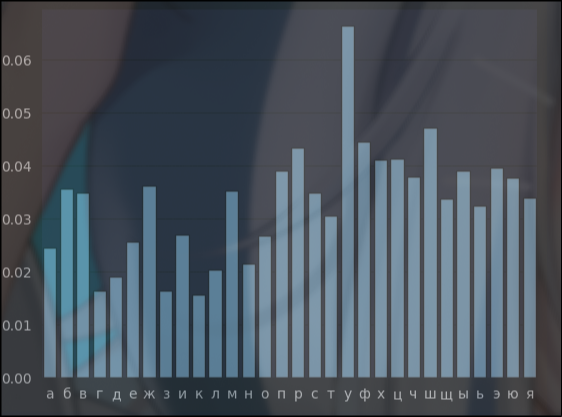

 0.03414485696895922       0.097100782328578
 0.04171231487117062       0.06410287225093138
 0.0358187872061346       0.05914323009374629
 0.05094339622641509       0.06718414139001673
 0.04022437531871494       0.06472657499200511
 0.03367823087847434       0.07169811320754718
 0.04048954614992351       0.048352201257861625
 0.03610402855685875       0.04830643328029098
 0.054048118199061586       0.058613085028179336
 0.039213337326544875       0.051105835311758094
 0.035521755872160186       0.04024390243902438
 0.05482127619228217       0.041509433962264135
 0.04457663351612603       0.04921290610695546
 0.05487816440694036       0.056603773584905676
 0.05125461972378915       0.04233962264150943
 0.0484305712546735       0.05172327044025157
 0.07962264150943395       0.04435836561289517
 0.052145859810343156       0.06269956458635703
 0.04822447992259313       0.04994301633531722
 0.05471698113207547       0.04176100628930818
 0.053786872176454975       0.05027225528681778
 0.05804132973944293       0.0448271495504622
 0.0389937106918239       0.06676532248119374
 0.03969736596301139       0.04844000493279073
 0.04750744786494538       0.043514150943396224
 0.04126727878115225       0.06692904271327701
 0.032999999999999995       0.05418596768726698
 0.03372641509433963       0.06699849519620327
 0.040570639668660834       0.06293288750895633
        0.05806317106223286